Hierarchical Clustering Silhouette Score: 0.4466890410285909


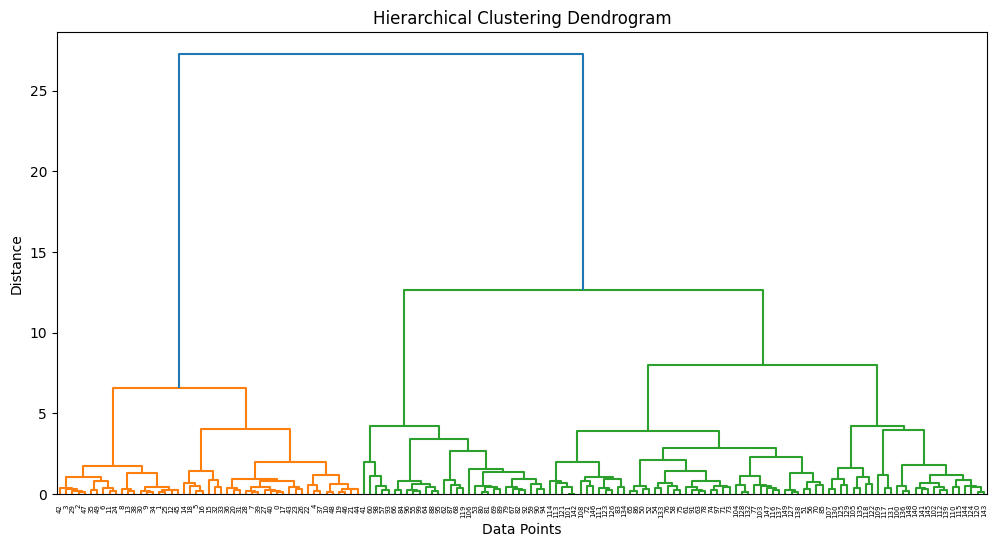


K-Means Silhouette Score: 0.45994823920518635


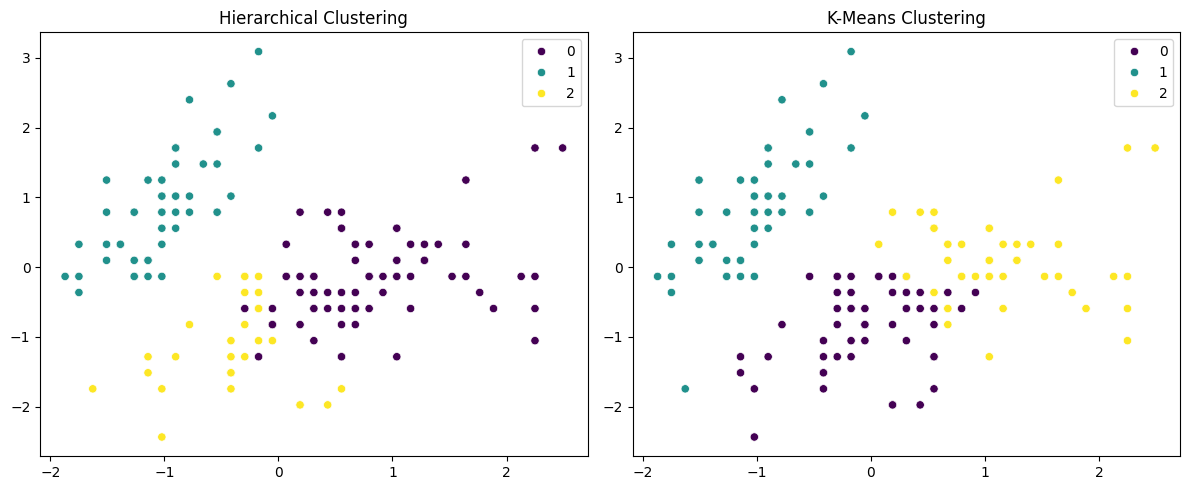

In [1]:

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

# Load Iris dataset
data = load_iris()
X = data.data

# Standardize data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Hierarchical Clustering
hierarchical = AgglomerativeClustering(n_clusters=3)
hier_clusters = hierarchical.fit_predict(X_scaled)

print("Hierarchical Clustering Silhouette Score:",
      silhouette_score(X_scaled, hier_clusters))

# Dendrogram
linked = linkage(X_scaled, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(linked)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

# K-Means Clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_clusters = kmeans.fit_predict(X_scaled)

print("\nK-Means Silhouette Score:",
      silhouette_score(X_scaled, kmeans_clusters))

# Compare clustering methods
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.scatterplot(
    x=X_scaled[:, 0], y=X_scaled[:, 1],
    hue=hier_clusters, palette='viridis'
)
plt.title("Hierarchical Clustering")

plt.subplot(1, 2, 2)
sns.scatterplot(
    x=X_scaled[:, 0], y=X_scaled[:, 1],
    hue=kmeans_clusters, palette='viridis'
)
plt.title("K-Means Clustering")

plt.tight_layout()
plt.show()
